We first make the experiment reproducible, then clean the articles, train the model, and evaluate it on data the model has never seen.

In [12]:
# Set every random source to 42 so another run follows the same setup.
import os
import random
import re

os.environ["PYTHONHASHSEED"] = "42"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Bidirectional, Dense, Dropout, Embedding, Input, LSTM
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.regularizers import l2

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")

TensorFlow version: 2.20.0
scikit-learn version: 1.6.1


In [13]:
# Fake articles receive label 1; reliable articles receive label 0.
fake_df = pd.read_csv("Fake.csv")
true_df = pd.read_csv("True.csv")

fake_df["label"] = 1
true_df["label"] = 0

# Reuters appears in the source data as a shortcut the model could memorize.
reuters_pattern = r"^.*?\(Reuters\)\s*-\s*"

for frame in (fake_df, true_df):
    frame["title"] = frame["title"].fillna("").astype(str)
    frame["text"] = frame["text"].fillna("").astype(str)
    frame["text"] = frame["text"].str.replace(
        reuters_pattern,
        "",
        regex=True,
        flags=re.IGNORECASE,
    )
    # Remove common web noise before building the final article text.
    frame["text"] = frame["text"].str.replace(r"<.*?>", "", regex=True)
    frame["text"] = frame["text"].str.replace(r"http\S+", "", regex=True)
    frame["article_text"] = (frame["title"] + " " + frame["text"]).str.strip()

df = pd.concat([fake_df, true_df], ignore_index=True)
# Remove repeated articles so the same example cannot appear in both splits.
df = df[["article_text", "label"]].drop_duplicates(subset="article_text")
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Final dataset size: {len(df):,} articles")
print("Final class balance:")
print(df["label"].value_counts().sort_index().rename(index={0: "Real", 1: "Fake"}))

display(df.head())

texts = df["article_text"].to_numpy()
labels = df["label"].to_numpy()

Final dataset size: 39,103 articles
Final class balance:
label
Real    21196
Fake    17907
Name: count, dtype: int64


,article_text,label
0,First Somali Refugee Elected In American Histo...,1
1,MY LAST VIDEO EVER?…Paul Joseph Watson Explain...,1
2,GOP Third-Party Candidate Live-Tweets Trump’s ...,1
3,BREAKING NEWS: Woman Who Narrated BRUTAL TORTU...,1
4,Iran warns U.S. against imposing further sanct...,0


We split the raw articles before tokenization. This keeps information from the validation and test sets out of the training vocabulary.

In [14]:
# Keep 70% for learning, 15% for tuning, and 15% for the final test.
# Stratification keeps the Real/Fake proportions similar in all three groups.
VOCAB_SIZE = 10000
MAX_LENGTH = 200
EMBEDDING_DIM = 100

X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    texts,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels,
)
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp,
)

# Learn the vocabulary from training articles only to avoid data leakage.
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

def tokenize_and_pad(texts_to_transform):
    sequences = tokenizer.texts_to_sequences(texts_to_transform)
    return pad_sequences(
        sequences,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post",
    )

# Neural networks need fixed-length integer sequences rather than raw strings.
X_train = tokenize_and_pad(X_train_text)
X_val = tokenize_and_pad(X_val_text)
X_test = tokenize_and_pad(X_test_text)

print(f"Train: {len(X_train):,} articles")
print(f"Validation: {len(X_val):,} articles")
print(f"Test: {len(X_test):,} articles")

Train: 27,372 articles
Validation: 5,865 articles
Test: 5,866 articles


# The Bi-LSTM reads each article from both directions. Padding is ignored, while L2 regularization and dropout help control overfitting.

In [15]:
# Input: padded word IDs. Embedding: learn a vector for each word.
# Bi-LSTM: use both past and future context. Dense and sigmoid: make the final 0/1 decision.
model = Sequential([
    Input(shape=(MAX_LENGTH,)),
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
    ),
    Bidirectional(LSTM(64)),
    Dense(32, activation="relu", kernel_regularizer=l2(1e-4)),
    Dropout(0.5),
    Dense(1, activation="sigmoid"),
])

# Binary cross-entropy fits the two-class Real/Fake prediction task.
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,088,641 (4.15 MB)

 Trainable params: 1,088,641 (4.15 MB)

 Non-trainable params: 0 (0.00 B)

# We train on the training set and watch validation loss. Early stopping keeps the best version instead of training longer than necessary.

In [17]:
# Stop when validation loss stops improving and restore the best model weights.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

# Lower the learning rate when progress stalls, allowing finer adjustments.
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=1,
    min_lr=1e-6,
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr],
)

Epoch 1/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 69s 162ms/step - accuracy: 0.9993 - loss: 0.0081 - val_accuracy: 0.9913 - val_loss: 0.0381 - learning_rate: 8.0000e-06
Epoch 2/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 70s 163ms/step - accuracy: 0.9993 - loss: 0.0078 - val_accuracy: 0.9911 - val_loss: 0.0386 - learning_rate: 8.0000e-06
Epoch 3/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 65s 152ms/step - accuracy: 0.9993 - loss: 0.0077 - val_accuracy: 0.9913 - val_loss: 0.0387 - learning_rate: 1.6000e-06


# The test set is used only at the end. These results show how well the trained model generalizes to unseen articles.

Test loss: 0.0384
Test accuracy: 0.9911


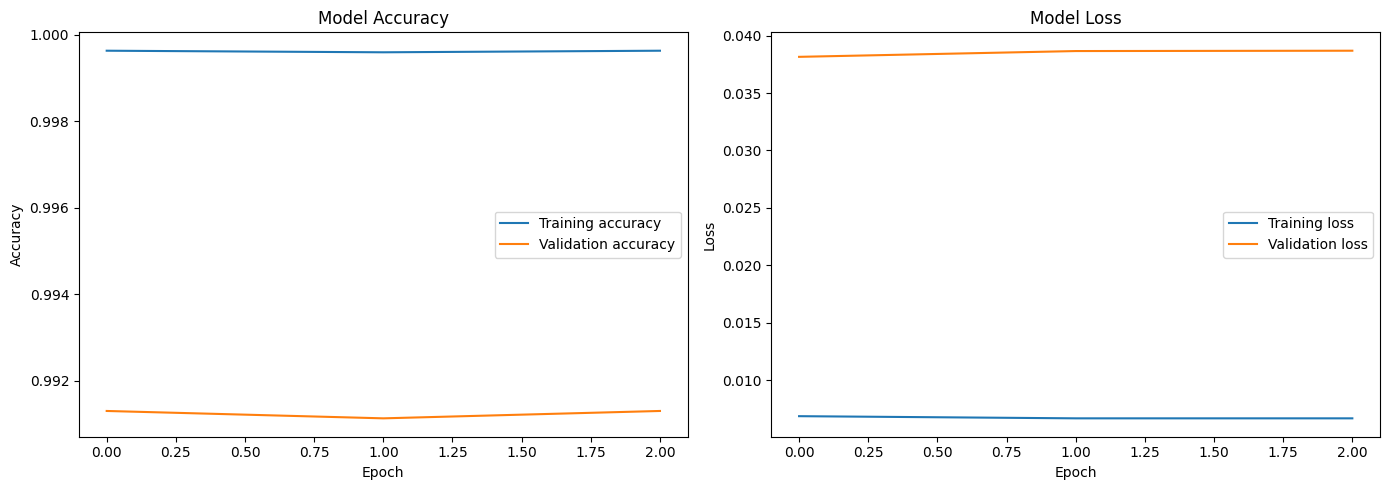

Classification report:
              precision    recall  f1-score   support

    Real (0)       0.99      0.99      0.99      3180
    Fake (1)       0.99      0.99      0.99      2686

    accuracy                           0.99      5866
   macro avg       0.99      0.99      0.99      5866
weighted avg       0.99      0.99      0.99      5866



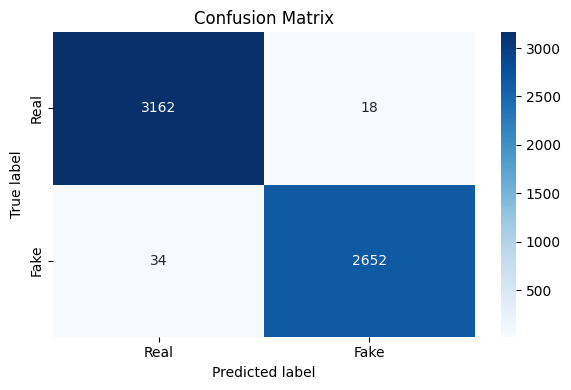

In [18]:
# Evaluate once on articles the model never saw during training.
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

# Convert probabilities into class labels using a 0.5 decision threshold.
y_pred = (model.predict(X_test, verbose=0).ravel() > 0.5).astype(int)

# These curves help us compare learning on training data with generalization.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history["accuracy"], label="Training accuracy")
ax1.plot(history.history["val_accuracy"], label="Validation accuracy")
ax1.set_title("Model Accuracy")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend()

ax2.plot(history.history["loss"], label="Training loss")
ax2.plot(history.history["val_loss"], label="Validation loss")
ax2.set_title("Model Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()

plt.tight_layout()
plt.show()

# Precision, recall, and F1-score show performance for each class.
print("Classification report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Real (0)", "Fake (1)"],
    )
)

# Rows are the true labels; columns are the model's predictions.
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"],
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

In [19]:
import pickle

# Save the trained model so it can be reused without retraining.
model.save("fake_news_bilstm.keras")

# Save the tokenizer because future text must use the same word-to-number mapping.
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Saved fake_news_bilstm.keras and tokenizer.pkl")

Saved fake_news_bilstm.keras and tokenizer.pkl


# This final demo uses the same tokenizer and padding process to classify new, unseen article text.

In [20]:
def predict_article(text):
    # Apply the same preprocessing used for the training articles.
    sequence = tokenizer.texts_to_sequences([text])
    padded_sequence = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post",
    )

    fake_probability = model.predict(padded_sequence, verbose=0)[0][0]
    label = "Fake News" if fake_probability > 0.5 else "Real News"

    print(f"Text: {text[:80]}...")
    print(f"Prediction: {label} (Fake probability: {fake_probability:.2%})\n")


predict_article("Aliens have landed in Washington D.C. and are demanding free pizza.")
predict_article("The Federal Reserve announced a 0.5% interest rate hike on Wednesday.")

Text: Aliens have landed in Washington D.C. and are demanding free pizza....
Prediction: Fake News (Fake probability: 99.98%)

Text: The Federal Reserve announced a 0.5% interest rate hike on Wednesday....
Prediction: Real News (Fake probability: 17.64%)

